In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Sales Forecasting & Business Analytics")
print("Libraries imported successfully!")

Sales Forecasting & Business Analytics
Libraries imported successfully!


In [4]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Nombre de lignes et colonnes :", df.shape)

print("\nNoms des colonnes :")
print(df.columns.tolist())

print("\nInformations sur les données :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum())

Nombre de lignes et colonnes : (541909, 8)

Noms des colonnes :
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Informations sur les données :
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Valeurs manquantes :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            

In [6]:
# 1. Nombre de doublons
print("Doublons avant nettoyage :", df.duplicated().sum())

# 2. Suppression des doublons
df = df.drop_duplicates()

# 3. Suppression des lignes sans date
df = df.dropna(subset=["InvoiceDate"])

# 4. Vérification après nettoyage
print("Dimensions après nettoyage :", df.shape)
print("Valeurs manquantes restantes :")
print(df.isnull().sum())

Doublons avant nettoyage : 5268
Dimensions après nettoyage : (536641, 8)
Valeurs manquantes restantes :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [7]:
# Calculer le montant total de chaque transaction
df["TotalSales"] = df["Quantity"] * df["UnitPrice"]

# Afficher les premières lignes
df[["InvoiceDate", "Quantity", "UnitPrice", "TotalSales"]].head()

,InvoiceDate,Quantity,UnitPrice,TotalSales
0,2010-12-01 08:26:00,6,2.55,15.30
1,2010-12-01 08:26:00,6,3.39,20.34
2,2010-12-01 08:26:00,8,2.75,22.00
3,2010-12-01 08:26:00,6,3.39,20.34
4,2010-12-01 08:26:00,6,3.39,20.34


In [8]:
# Extraire le mois et l'année
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculer les ventes mensuelles
monthly_sales = df.groupby("YearMonth")["TotalSales"].sum()

# Afficher les résultats
print(monthly_sales)

YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: TotalSales, dtype: float64


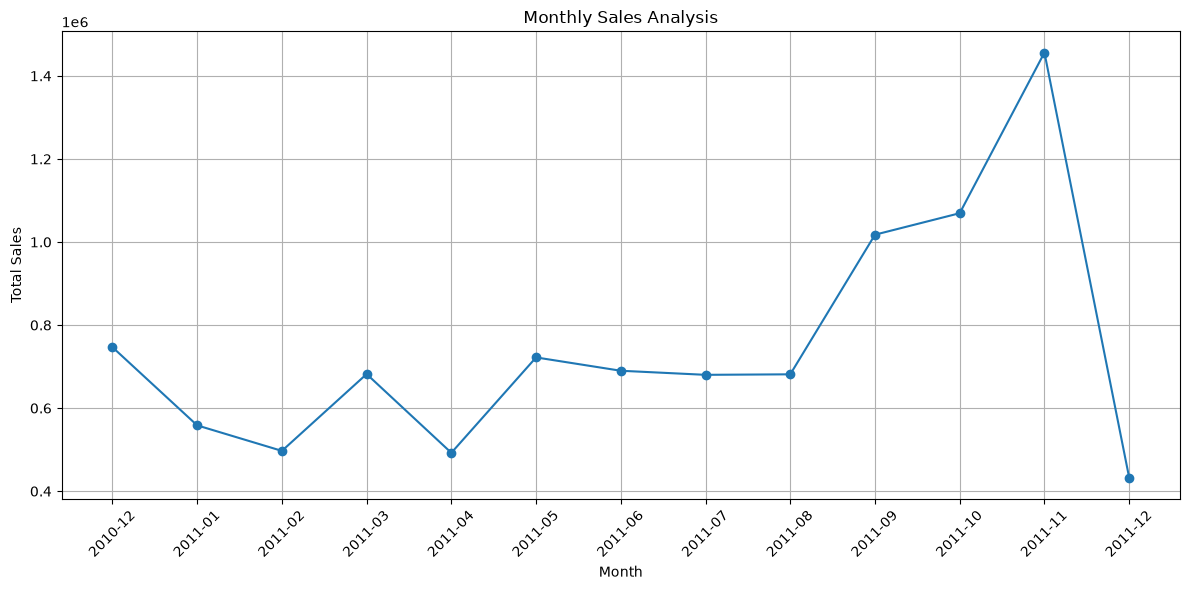

In [9]:
plt.figure(figsize=(12, 6))

monthly_sales.index = monthly_sales.index.astype(str)

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# Calculer les ventes par produit
product_sales = (
    df.groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Afficher les 10 produits les plus rentables
top_products = product_sales.head(10)

print(top_products)

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: TotalSales, dtype: float64


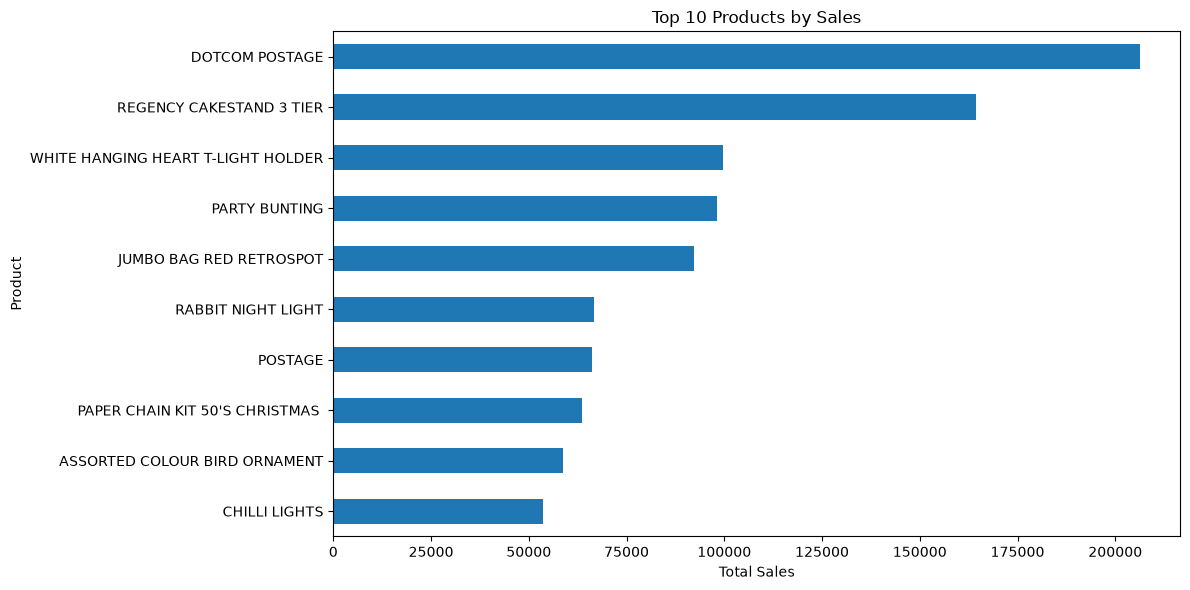

In [11]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [12]:
# Calculer les ventes par pays
country_sales = (
    df.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Afficher les 10 premiers pays
top_countries = country_sales.head(10)

print(top_countries)

Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: TotalSales, dtype: float64


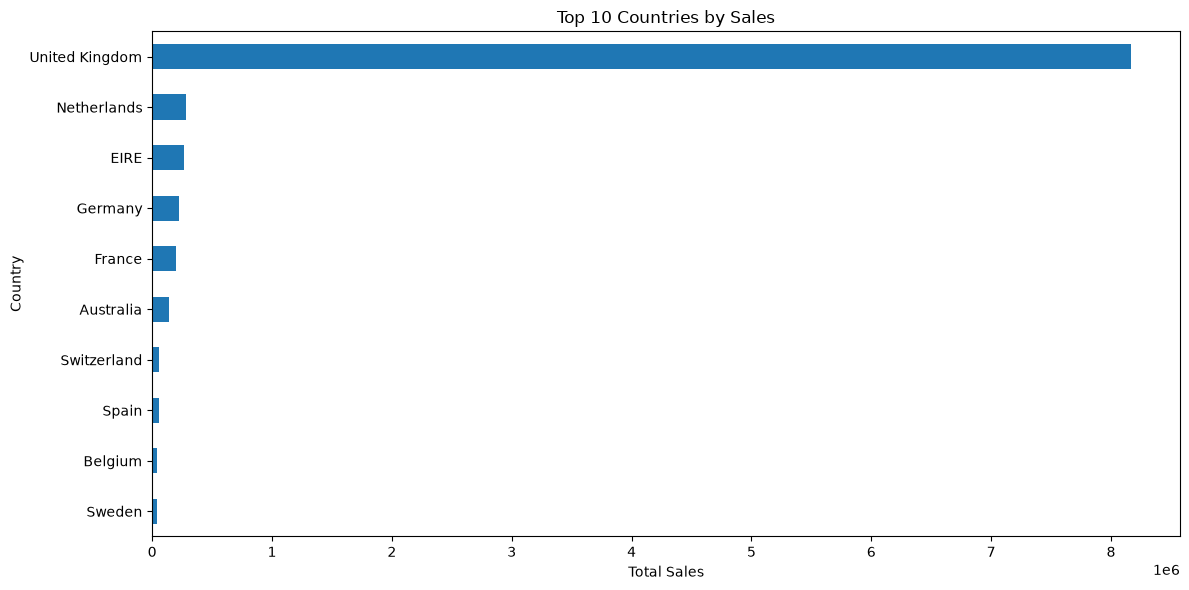

In [13]:
plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [14]:
# Convertir la date en format datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Garder les ventes positives uniquement
sales_data = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculer le chiffre d'affaires
sales_data["TotalSales"] = (
    sales_data["Quantity"] * sales_data["UnitPrice"]
)

# Regrouper les ventes par jour
daily_sales = (
    sales_data
    .set_index("InvoiceDate")["TotalSales"]
    .resample("D")
    .sum()
)

print("Nombre de jours :", len(daily_sales))
print("\nPremières valeurs :")
print(daily_sales.head())

Nombre de jours : 374

Premières valeurs :
InvoiceDate
2010-12-01    58776.79
2010-12-02    47629.42
2010-12-03    46898.63
2010-12-04        0.00
2010-12-05    31364.63
Freq: D, Name: TotalSales, dtype: float64


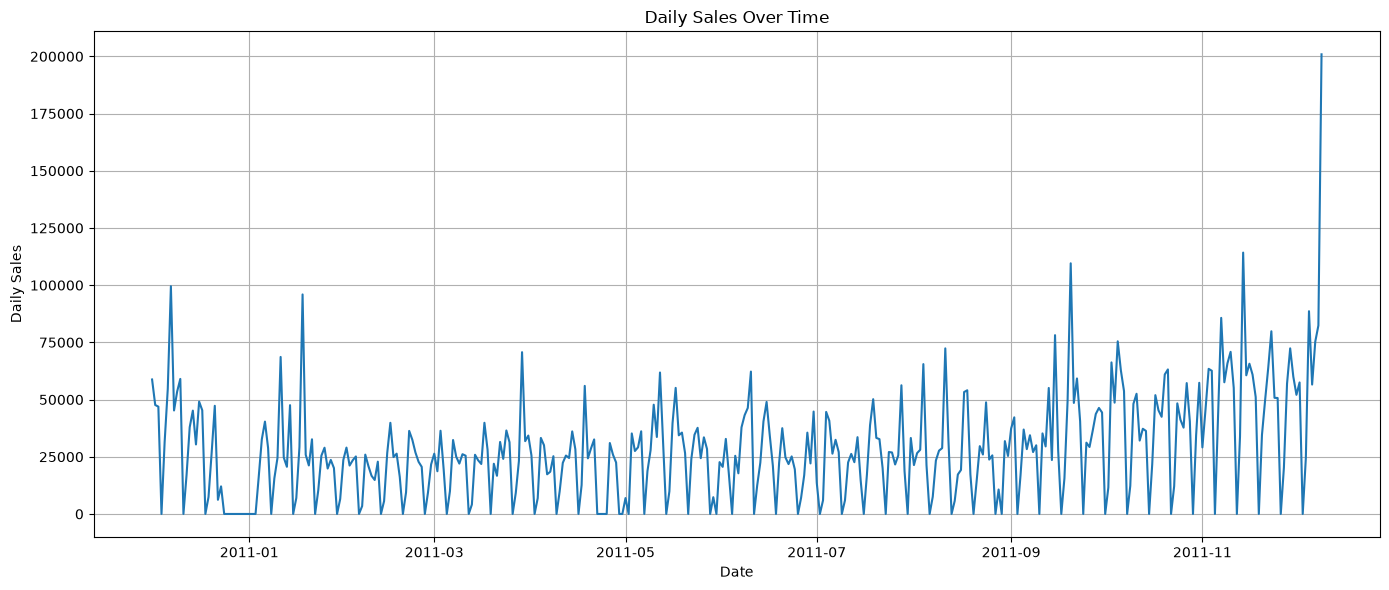

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# Créer un tableau pour la prédiction
forecast_data = pd.DataFrame(index=daily_sales.index)

# Ajouter les ventes du jour précédent
forecast_data["Sales_Lag_1"] = daily_sales.shift(1)

# Ajouter les ventes d'il y a 7 jours
forecast_data["Sales_Lag_7"] = daily_sales.shift(7)

# Ajouter la moyenne des 7 jours précédents
forecast_data["Sales_Rolling_Mean_7"] = (
    daily_sales.shift(1).rolling(window=7).mean()
)

# Ajouter les ventes à prédire
forecast_data["Target"] = daily_sales

# Supprimer les lignes incomplètes
forecast_data = forecast_data.dropna()

print("Dimensions :", forecast_data.shape)
display(forecast_data.head())

Dimensions : (367, 4)


,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_Mean_7,Target
InvoiceDate,,,,
2010-12-08,99553.85,58776.79,48406.781429,45235.36
2010-12-09,45235.36,47629.42,46472.291429,53548.19
2010-12-10,53548.19,46898.63,47317.830000,59021.02
2010-12-11,59021.02,0.00,49049.600000,0.00
2010-12-12,0.00,31364.63,49049.600000,17125.65


In [17]:
# Définir les variables explicatives et la cible
X = forecast_data[
    ["Sales_Lag_1", "Sales_Lag_7", "Sales_Rolling_Mean_7"]
]

y = forecast_data["Target"]

# Séparer les données dans l'ordre chronologique
split_index = int(len(forecast_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Taille des données d'entraînement :", len(X_train))
print("Taille des données de test :", len(X_test))

Taille des données d'entraînement : 293
Taille des données de test : 74


In [18]:
from sklearn.ensemble import RandomForestRegressor

# Créer le modèle
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Entraîner le modèle
model.fit(X_train, y_train)

print("Modèle entraîné avec succès !")

Modèle entraîné avec succès !


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Prédire les ventes sur les données de test
y_pred = model.predict(X_test)

# Calculer les métriques d'évaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE) :", round(mae, 2))
print("Root Mean Squared Error (RMSE) :", round(rmse, 2))

Mean Absolute Error (MAE) : 14673.35
Root Mean Squared Error (RMSE) : 25045.42


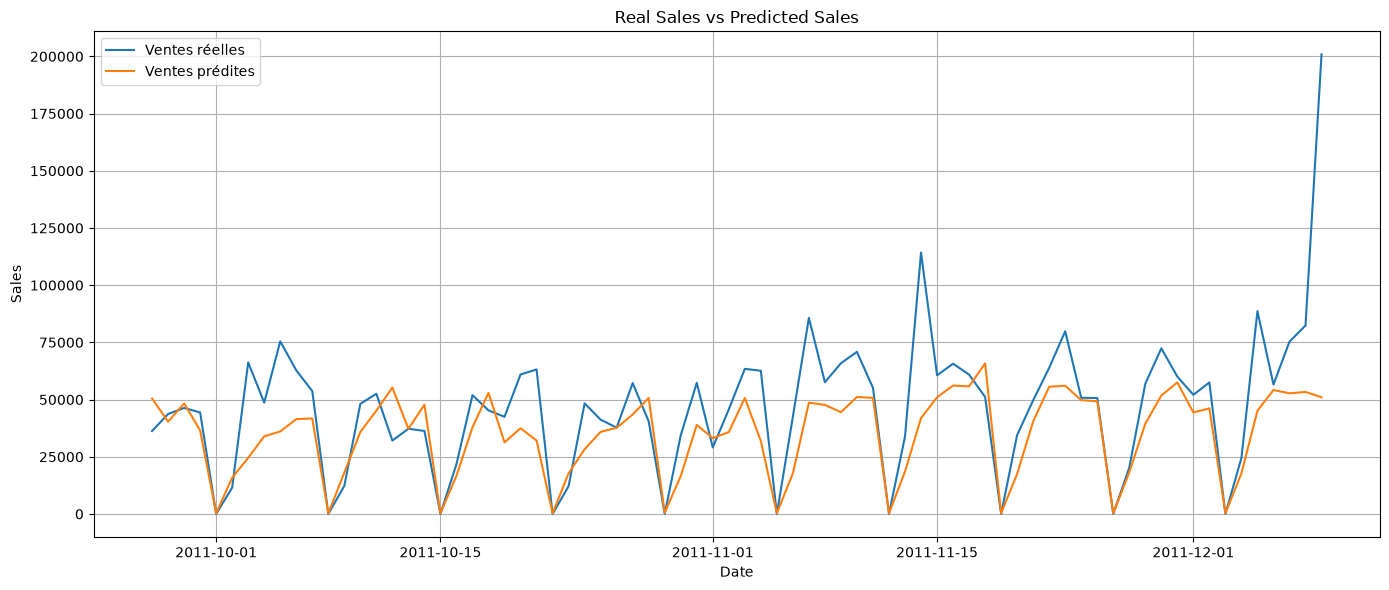

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Ventes réelles"
)

plt.plot(
    y_test.index,
    y_pred,
    label="Ventes prédites"
)

plt.title("Real Sales vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

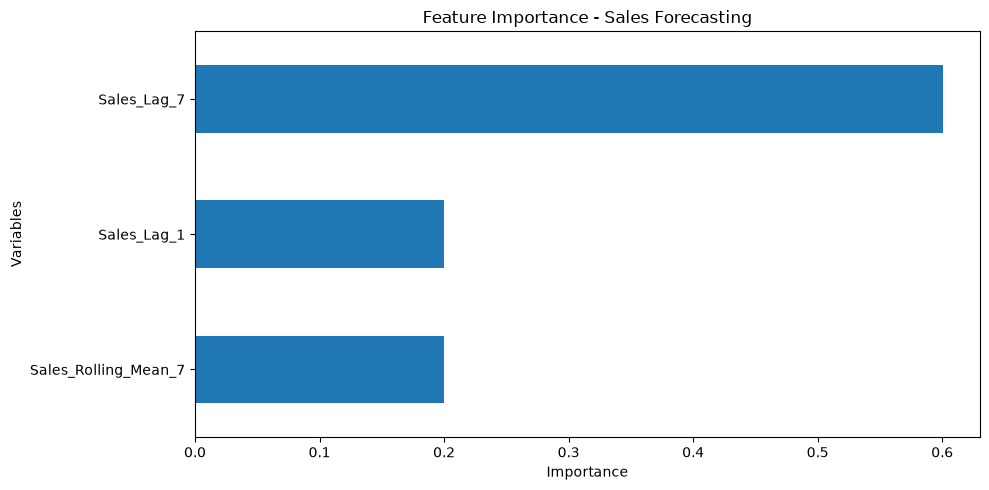

Sales_Lag_7             0.600322
Sales_Lag_1             0.200049
Sales_Rolling_Mean_7    0.199630
dtype: float64


In [21]:
# Importance des variables
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

# Visualisation
plt.figure(figsize=(10, 5))

importance.plot(kind="barh")

plt.title("Feature Importance - Sales Forecasting")
plt.xlabel("Importance")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))

In [22]:
# Créer un tableau de comparaison
results = pd.DataFrame({
    "Date": y_test.index,
    "Real_Sales": y_test.values,
    "Predicted_Sales": y_pred
})

# Sauvegarder les résultats
results.to_csv("sales_forecast_results.csv", index=False)

print("Fichier enregistré avec succès !")
display(results.head(10))

Fichier enregistré avec succès !


,Date,Real_Sales,Predicted_Sales
0,2011-09-27,36260.91,50468.22393
1,2011-09-28,43693.08,40312.66423
2,2011-09-29,46343.35,48331.09280
3,2011-09-30,44347.06,36486.05880
4,2011-10-01,0.00,288.36590
5,2011-10-02,11531.56,15867.89070
6,2011-10-03,66243.94,24537.34660
7,2011-10-04,48652.54,33947.89230
8,2011-10-05,75460.77,36054.87720
9,2011-10-06,62761.92,41441.81890


In [23]:
# Créer un résumé des résultats
summary = pd.DataFrame({
    "Metric": [
        "Nombre de jours analysés",
        "Nombre de jours de test",
        "MAE",
        "RMSE"
    ],
    "Value": [
        len(daily_sales),
        len(y_test),
        round(mae, 2),
        round(rmse, 2)
    ]
})

# Enregistrer le rapport
summary.to_csv("sales_forecasting_summary.csv", index=False)

display(summary)

print("Rapport sauvegardé avec succès !")

,Metric,Value
0,Nombre de jours analysés,374.00
1,Nombre de jours de test,74.00
2,MAE,14673.35
3,RMSE,25045.42


Rapport sauvegardé avec succès !
